# TP2 — Tokenisation et vectorisation
### One-hot Encoding · Bag of Words (BoW) · TF-IDF

**Université Ibnou Zohr — Centre d’Excellence IT**  
**Filière : ADIA — Master S3**  
**Enseignant : Pr. O. Maarouf**

## Objectifs
Ce notebook reprend les questions du TP et propose une résolution progressive :
1. Tokeniser les quatre documents et construire le vocabulaire.
2. Calculer les représentations One-hot et BoW, puis expliquer TF-IDF.
3. Implémenter les fonctions en Python avec NumPy.
4. Tester Doc1 et comparer les résultats à la théorie.

> Convention utilisée : les textes sont mis en minuscules, la ponctuation est ignorée et les séquences de lettres sont extraites. Le terme `world-renowned` est donc séparé en `world` et `renowned`. Pour TF-IDF, TF est la fréquence brute et IDF = ln(N / DF), sans lissage ni normalisation.

## 0. Préparation de l’environnement
Nous utiliserons `re` pour la tokenisation, `Counter` pour les fréquences, `NumPy` pour les vecteurs et `pandas`/`matplotlib` pour présenter les tableaux et visualisations.

Si nécessaire, installez les bibliothèques dans une cellule séparée avec ` %pip install numpy pandas matplotlib `.

In [1]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 70)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 160)

print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)

NumPy : 2.1.3
Pandas : 2.2.3


## Corpus fourni dans l’énoncé
Nous définissons les quatre documents tels qu’ils apparaissent dans le sujet.

In [2]:
doc1 = """London is the capital of the United Kingdom. It has a rich history and many landmarks. Tourists love visiting Big Ben and the Tower of London."""
doc2 = """New York is a bustling city in the United States. Known for its skyscrapers and diverse culture. Central Park is a green oasis in the urban jungle."""
doc3 = """Paris is the city of lights in France. Famous for the Eiffel Tower and fine cuisine. The Louvre Museum houses world-renowned art."""
doc4 = """Tokyo is the vibrant capital of Japan. It blends tradition with modern technology. Shibuya Crossing is one of the busiest intersections in the world."""

documents = {
    "Doc1 — London": doc1,
    "Doc2 — New York": doc2,
    "Doc3 — Paris": doc3,
    "Doc4 — Tokyo": doc4,
}
corpus = list(documents.values())
pd.DataFrame({"Document": list(documents.keys()), "Texte": corpus})

,Document,Texte
0,Doc1 — London,London is the capital of the United Kingdom. I...
1,Doc2 — New York,New York is a bustling city in the United Stat...
2,Doc3 — Paris,Paris is the city of lights in France. Famous ...
3,Doc4 — Tokyo,Tokyo is the vibrant capital of Japan. It blen...


# Question 1 — Tokenisation et construction du vocabulaire

### Explication
La tokenisation découpe un document en tokens (ici, des mots). On passe le texte en minuscules et on ignore la ponctuation. Les répétitions restent présentes dans chaque document tokenisé. Le vocabulaire, lui, ne conserve chaque mot qu’une seule fois.

### Réponse / code
La fonction `tokenize_doc` est appliquée aux quatre documents, puis nous construisons un vocabulaire global en gardant l’ordre de première apparition.

In [3]:
def tokenize_doc(doc):
    """Convertit en minuscules et extrait les séquences de lettres."""
    return re.findall(r"[a-z]+", doc.lower())

tokenized_corpus = [tokenize_doc(doc) for doc in corpus]

for name, tokens in zip(documents.keys(), tokenized_corpus):
    print(f"{name}: {len(tokens)} tokens")
    print(tokens, "\\n")

vocab = list(dict.fromkeys(token for tokens in tokenized_corpus for token in tokens))
vocab_index = {word: i for i, word in enumerate(vocab)}

print("Taille du vocabulaire :", len(vocab))
print("Vocabulaire (index → mot) :")
display(pd.DataFrame({"Index": range(len(vocab)), "Mot": vocab}))

Doc1 — London: 26 tokens
['london', 'is', 'the', 'capital', 'of', 'the', 'united', 'kingdom', 'it', 'has', 'a', 'rich', 'history', 'and', 'many', 'landmarks', 'tourists', 'love', 'visiting', 'big', 'ben', 'and', 'the', 'tower', 'of', 'london'] \n
Doc2 — New York: 27 tokens
['new', 'york', 'is', 'a', 'bustling', 'city', 'in', 'the', 'united', 'states', 'known', 'for', 'its', 'skyscrapers', 'and', 'diverse', 'culture', 'central', 'park', 'is', 'a', 'green', 'oasis', 'in', 'the', 'urban', 'jungle'] \n
Doc3 — Paris: 23 tokens
['paris', 'is', 'the', 'city', 'of', 'lights', 'in', 'france', 'famous', 'for', 'the', 'eiffel', 'tower', 'and', 'fine', 'cuisine', 'the', 'louvre', 'museum', 'houses', 'world', 'renowned', 'art'] \n
Doc4 — Tokyo: 24 tokens
['tokyo', 'is', 'the', 'vibrant', 'capital', 'of', 'japan', 'it', 'blends', 'tradition', 'with', 'modern', 'technology', 'shibuya', 'crossing', 'is', 'one', 'of', 'the', 'busiest', 'intersections', 'in', 'the', 'world'] \n
Taille du vocabulaire : 6

,Index,Mot
0,0,london
1,1,is
2,2,the
3,3,capital
4,4,of
5,5,united
6,6,kingdom
7,7,it
8,8,has
9,9,a


### Visualisation 1 — Nombre de tokens par document
Ce graphique compare la longueur des documents après tokenisation. Le nombre de tokens compte les répétitions, contrairement à la taille du vocabulaire.

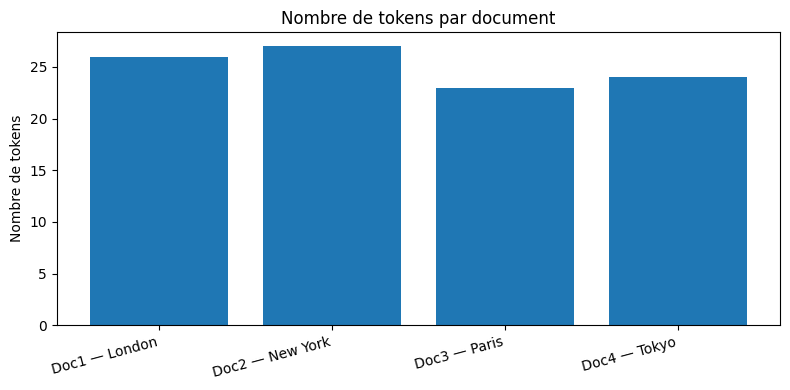

Résumé :


,Document,Nombre de tokens,Mots distincts
0,Doc1 — London,26,21
1,Doc2 — New York,27,23
2,Doc3 — Paris,23,21
3,Doc4 — Tokyo,24,20


In [4]:
token_counts = [len(tokens) for tokens in tokenized_corpus]
plt.figure(figsize=(8, 4))
plt.bar(list(documents.keys()), token_counts)
plt.title("Nombre de tokens par document")
plt.ylabel("Nombre de tokens")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

print("Résumé :")
display(pd.DataFrame({
    "Document": list(documents.keys()),
    "Nombre de tokens": token_counts,
    "Mots distincts": [len(set(tokens)) for tokens in tokenized_corpus]
}))

# Question 2 — Calculs manuels des vecteurs

## 2.1 One-hot Encoding
Pour chaque mot du vocabulaire, la valeur vaut **1** si le mot apparaît dans le document, et **0** sinon. Les répétitions ne changent pas la valeur.

### Réponse / code
Nous construisons une matrice : une ligne par document, une colonne par mot du vocabulaire. Pour rendre les résultats lisibles, nous affichons d’abord une partie des colonnes puis la matrice complète peut être consultée avec `display`.

In [5]:
def one_hot_doc(tokens, vocab):
    present = set(tokens)
    return np.array([int(word in present) for word in vocab], dtype=int)

one_hot_matrix = np.vstack([
    one_hot_doc(tokens, vocab) for tokens in tokenized_corpus
])

one_hot_df = pd.DataFrame(one_hot_matrix, index=documents.keys(), columns=vocab)
print("Matrice One-hot — aperçu des 20 premiers mots :")
display(one_hot_df.iloc[:, :20])
print("Somme One-hot par document (= nombre de mots distincts) :")
display(one_hot_df.sum(axis=1).rename("Nombre de mots distincts").to_frame())

Matrice One-hot — aperçu des 20 premiers mots :


,london,is,the,capital,of,united,kingdom,it,has,a,rich,history,and,many,landmarks,tourists,love,visiting,big,ben
Doc1 — London,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
Doc2 — New York,0,1,1,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0
Doc3 — Paris,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
Doc4 — Tokyo,0,1,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0


Somme One-hot par document (= nombre de mots distincts) :


,Nombre de mots distincts
Doc1 — London,21
Doc2 — New York,23
Doc3 — Paris,21
Doc4 — Tokyo,20


## 2.2 Bag of Words (BoW)
BoW compte le nombre d’occurrences de chaque mot dans un document. Contrairement au One-hot, les répétitions augmentent la valeur.

### Réponse / code
La somme des composantes d’un vecteur BoW doit être égale au nombre total de tokens du document.

In [6]:
def bow_doc(tokens, vocab):
    counts = Counter(tokens)
    return np.array([counts[word] for word in vocab], dtype=int)

bow_matrix = np.vstack([
    bow_doc(tokens, vocab) for tokens in tokenized_corpus
])
bow_df = pd.DataFrame(bow_matrix, index=documents.keys(), columns=vocab)

print("Matrice BoW — aperçu des 20 premiers mots :")
display(bow_df.iloc[:, :20])
print("Vérification : somme des fréquences = nombre de tokens")
display(pd.DataFrame({
    "Somme BoW": bow_matrix.sum(axis=1),
    "Nombre de tokens": token_counts
}, index=documents.keys()))

Matrice BoW — aperçu des 20 premiers mots :


,london,is,the,capital,of,united,kingdom,it,has,a,rich,history,and,many,landmarks,tourists,love,visiting,big,ben
Doc1 — London,2,1,3,1,2,1,1,1,1,1,1,1,2,1,1,1,1,1,1,1
Doc2 — New York,0,2,2,0,0,1,0,0,0,2,0,0,1,0,0,0,0,0,0,0
Doc3 — Paris,0,1,3,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
Doc4 — Tokyo,0,2,3,1,2,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0


Vérification : somme des fréquences = nombre de tokens


,Somme BoW,Nombre de tokens
Doc1 — London,26,26
Doc2 — New York,27,27
Doc3 — Paris,23,23
Doc4 — Tokyo,24,24


### Visualisation 2 — Fréquences des mots les plus présents
Le graphique montre les mots les plus fréquents dans l’ensemble du corpus. Il permet d’identifier les mots communs, qui peuvent être moins discriminants.

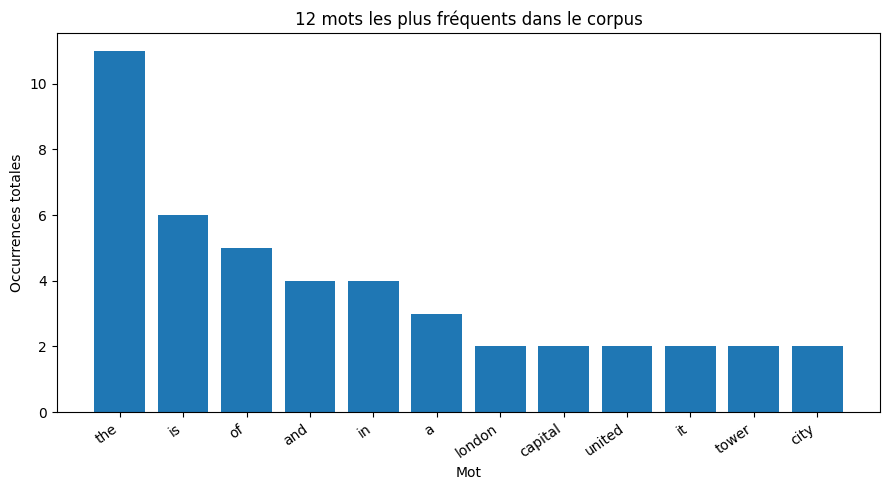

,Mot,Fréquence
0,the,11
1,is,6
2,of,5
3,and,4
4,in,4
5,a,3
6,london,2
7,capital,2
8,united,2
9,it,2


In [7]:
global_counts = Counter(token for tokens in tokenized_corpus for token in tokens)
top_words = global_counts.most_common(12)
top_df = pd.DataFrame(top_words, columns=["Mot", "Fréquence"])

plt.figure(figsize=(9, 5))
plt.bar(top_df["Mot"], top_df["Fréquence"])
plt.title("12 mots les plus fréquents dans le corpus")
plt.xlabel("Mot")
plt.ylabel("Occurrences totales")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
display(top_df)

## 2.3 TF-IDF
TF-IDF combine :
- **TF** : fréquence du terme dans le document ;
- **DF** : nombre de documents contenant le terme ;
- **IDF** : rareté du terme dans le corpus.

Pour ce TP, nous utilisons les formules suivantes :
\[
TF(t,d)=\text{nombre d’occurrences de }t\text{ dans }d
\]
\[
IDF(t)=\ln\left(\frac{N}{DF(t)}\right), \qquad
TFIDF(t,d)=TF(t,d)\times IDF(t)
\]
Ici, \(N=4\). L’IDF d’un mot présent dans les quatre documents vaut zéro ; un mot présent dans un seul document a un IDF égal à \(\ln(4)\approx1{,}3863\).

### Réponse / code
Les fonctions `tf` et `idf` sont séparées pour rendre les calculs transparents. Aucun lissage ni normalisation n’est appliqué.

In [8]:
def tf(term, tokens):
    return tokens.count(term)

def document_frequency(term, corpus_tokens):
    return sum(term in set(tokens) for tokens in corpus_tokens)

def idf(term, corpus_tokens):
    N = len(corpus_tokens)
    df = document_frequency(term, corpus_tokens)
    return np.log(N / df) if df > 0 else 0.0

def tfidf_doc(doc_tokens, corpus_tokens, vocab):
    return np.array([
        tf(word, doc_tokens) * idf(word, corpus_tokens)
        for word in vocab
    ], dtype=float)

tfidf_matrix = np.vstack([
    tfidf_doc(tokens, tokenized_corpus, vocab)
    for tokens in tokenized_corpus
])
tfidf_df = pd.DataFrame(tfidf_matrix, index=documents.keys(), columns=vocab)

# Tableau DF/IDF du vocabulaire
df_values = [document_frequency(word, tokenized_corpus) for word in vocab]
idf_values = [idf(word, tokenized_corpus) for word in vocab]
idf_table = pd.DataFrame({
    "Mot": vocab,
    "DF (documents)": df_values,
    "IDF": idf_values
})
display(idf_table.sort_values(["DF (documents)", "Mot"]).reset_index(drop=True).round(4))

,Mot,DF (documents),IDF
0,art,1,1.3863
1,ben,1,1.3863
2,big,1,1.3863
3,blends,1,1.3863
4,busiest,1,1.3863
5,bustling,1,1.3863
6,central,1,1.3863
7,crossing,1,1.3863
8,cuisine,1,1.3863
9,culture,1,1.3863


### Calcul manuel illustré sur Doc1
- `london` apparaît 2 fois et dans un seul document : TF = 2, DF = 1, IDF = ln(4) ≈ 1,3863, donc TF-IDF ≈ 2,7726.
- `is` apparaît dans les quatre documents : IDF = ln(4/4) = 0, donc TF-IDF = 0.
- Les mots absents de Doc1 ont TF = 0 et donc TF-IDF = 0.

Le tableau suivant donne les valeurs de TF, DF, IDF et TF-IDF pour les mots de Doc1.

In [9]:
doc1_tokens = tokenized_corpus[0]
doc1_terms = list(dict.fromkeys(doc1_tokens))
manual_rows = []
for word in doc1_terms:
    term_tf = tf(word, doc1_tokens)
    term_df = document_frequency(word, tokenized_corpus)
    term_idf = idf(word, tokenized_corpus)
    manual_rows.append({
        "Mot": word,
        "TF": term_tf,
        "DF": term_df,
        "IDF": term_idf,
        "TF-IDF": term_tf * term_idf
    })
doc1_tfidf_table = pd.DataFrame(manual_rows)
display(doc1_tfidf_table.round(4))

,Mot,TF,DF,IDF,TF-IDF
0,london,2,1,1.3863,2.7726
1,is,1,4,0.0000,0.0000
2,the,3,4,0.0000,0.0000
3,capital,1,2,0.6931,0.6931
4,of,2,3,0.2877,0.5754
5,united,1,2,0.6931,0.6931
6,kingdom,1,1,1.3863,1.3863
7,it,1,2,0.6931,0.6931
8,has,1,1,1.3863,1.3863
9,a,1,2,0.6931,0.6931


### Visualisation 3 — TF-IDF de Doc1
Les mots les plus pondérés sont généralement ceux qui sont spécifiques à Doc1. Les mots présents dans tous les documents ont un poids nul avec la formule IDF choisie.

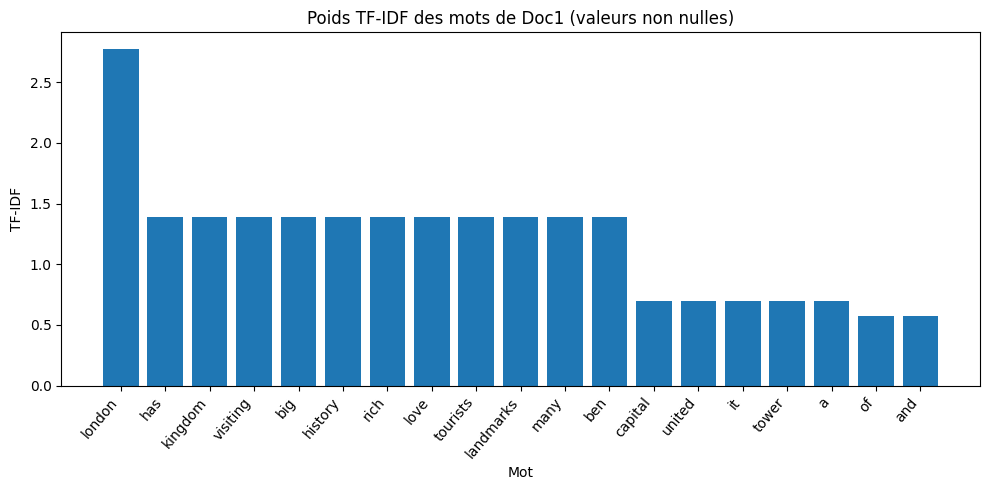

In [10]:
doc1_tfidf_nonzero = doc1_tfidf_table[doc1_tfidf_table["TF-IDF"] > 0].sort_values("TF-IDF", ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(doc1_tfidf_nonzero["Mot"], doc1_tfidf_nonzero["TF-IDF"])
plt.title("Poids TF-IDF des mots de Doc1 (valeurs non nulles)")
plt.xlabel("Mot")
plt.ylabel("TF-IDF")
plt.xticks(rotation=50, ha="right")
plt.tight_layout()
plt.show()

# Question 3 — Implémentation des fonctions demandées

Les fonctions `tokenize_doc`, `one_hot_doc`, `bow_doc` et `tfidf_doc` sont définies ci-dessus et réutilisées pour l’ensemble du corpus. Nous regroupons maintenant les matrices finales. Chaque matrice a 4 lignes (documents) et autant de colonnes que le vocabulaire contient de mots.

In [11]:
print("Dimensions des matrices :")
print("One-hot :", one_hot_matrix.shape)
print("BoW     :", bow_matrix.shape)
print("TF-IDF  :", tfidf_matrix.shape)

print("\nMatrice One-hot complète :")
display(one_hot_df)
print("Matrice BoW complète :")
display(bow_df)
print("Matrice TF-IDF complète (arrondie à 3 décimales) :")
display(tfidf_df.round(3))

Dimensions des matrices :
One-hot : (4, 65)
BoW     : (4, 65)
TF-IDF  : (4, 65)

Matrice One-hot complète :


,london,is,the,capital,of,united,kingdom,it,has,a,rich,history,and,many,landmarks,tourists,love,visiting,big,ben,tower,new,york,bustling,city,in,states,known,for,its,skyscrapers,diverse,culture,central,park,green,oasis,urban,jungle,paris,lights,france,famous,eiffel,fine,cuisine,louvre,museum,houses,world,renowned,art,tokyo,vibrant,japan,blends,tradition,with,modern,technology,shibuya,crossing,one,busiest,intersections
Doc1 — London,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Doc2 — New York,0,1,1,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Doc3 — Paris,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
Doc4 — Tokyo,0,1,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1


Matrice BoW complète :


,london,is,the,capital,of,united,kingdom,it,has,a,rich,history,and,many,landmarks,tourists,love,visiting,big,ben,tower,new,york,bustling,city,in,states,known,for,its,skyscrapers,diverse,culture,central,park,green,oasis,urban,jungle,paris,lights,france,famous,eiffel,fine,cuisine,louvre,museum,houses,world,renowned,art,tokyo,vibrant,japan,blends,tradition,with,modern,technology,shibuya,crossing,one,busiest,intersections
Doc1 — London,2,1,3,1,2,1,1,1,1,1,1,1,2,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Doc2 — New York,0,2,2,0,0,1,0,0,0,2,0,0,1,0,0,0,0,0,0,0,0,1,1,1,1,2,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Doc3 — Paris,0,1,3,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
Doc4 — Tokyo,0,2,3,1,2,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1


Matrice TF-IDF complète (arrondie à 3 décimales) :


,london,is,the,capital,of,united,kingdom,it,has,a,rich,history,and,many,landmarks,tourists,love,visiting,big,ben,tower,new,york,bustling,city,in,states,known,for,its,skyscrapers,diverse,culture,central,park,green,oasis,urban,jungle,paris,lights,france,famous,eiffel,fine,cuisine,louvre,museum,houses,world,renowned,art,tokyo,vibrant,japan,blends,tradition,with,modern,technology,shibuya,crossing,one,busiest,intersections
Doc1 — London,2.773,0.0,0.0,0.693,0.575,0.693,1.386,0.693,1.386,0.693,1.386,1.386,0.575,1.386,1.386,1.386,1.386,1.386,1.386,1.386,0.693,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Doc2 — New York,0.000,0.0,0.0,0.000,0.000,0.693,0.000,0.000,0.000,1.386,0.000,0.000,0.288,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.386,1.386,1.386,0.693,0.575,1.386,1.386,0.693,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Doc3 — Paris,0.000,0.0,0.0,0.000,0.288,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.288,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.693,0.000,0.000,0.000,0.693,0.288,0.000,0.000,0.693,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,0.693,1.386,1.386,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Doc4 — Tokyo,0.000,0.0,0.0,0.693,0.575,0.000,0.000,0.693,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.288,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.693,0.000,0.000,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386,1.386


# Question 4 — Test sur Doc1 et comparaison

Nous vérifions les propriétés attendues :
- somme One-hot = nombre de mots distincts ;
- somme BoW = nombre de tokens ;
- le poids TF-IDF de `london` vaut environ 2,7726 ;
- le poids TF-IDF de `is` vaut zéro.

Ces assertions servent de tests automatiques. Si elles passent, les fonctions respectent les conventions annoncées dans ce notebook.

In [12]:
one_hot_doc1 = one_hot_doc(doc1_tokens, vocab)
bow_doc1 = bow_doc(doc1_tokens, vocab)
tfidf_doc1 = tfidf_doc(doc1_tokens, tokenized_corpus, vocab)

idx_london = vocab_index["london"]
idx_is = vocab_index["is"]

checks = {
    "Nombre de tokens Doc1 = 26": len(doc1_tokens) == 26,
    "Vocabulaire global = 65 mots": len(vocab) == 65,
    "Somme One-hot = mots distincts": one_hot_doc1.sum() == len(set(doc1_tokens)),
    "Somme BoW = tokens": bow_doc1.sum() == len(doc1_tokens),
    "TF-IDF london ≈ 2.7726": np.isclose(tfidf_doc1[idx_london], 2 * np.log(4)),
    "TF-IDF is = 0": np.isclose(tfidf_doc1[idx_is], 0.0),
}
display(pd.DataFrame({"Test": list(checks.keys()), "Réussi": list(checks.values())}))
assert all(checks.values()), "Au moins un test a échoué."
print("Tous les tests sont réussis.")

comparison = pd.DataFrame({
    "Méthode": ["One-hot", "BoW", "TF-IDF"],
    "Valeur pour 'london' dans Doc1": [
        one_hot_doc1[idx_london],
        bow_doc1[idx_london],
        tfidf_doc1[idx_london]
    ],
    "Interprétation": [
        "Présence du mot",
        "Nombre d’occurrences",
        "Fréquence pondérée par la rareté"
    ]
})
display(comparison.round(4))

,Test,Réussi
0,Nombre de tokens Doc1 = 26,True
1,Vocabulaire global = 65 mots,True
2,Somme One-hot = mots distincts,True
3,Somme BoW = tokens,True
4,TF-IDF london ≈ 2.7726,True
5,TF-IDF is = 0,True


Tous les tests sont réussis.


,Méthode,Valeur pour 'london' dans Doc1,Interprétation
0,One-hot,1.0000,Présence du mot
1,BoW,2.0000,Nombre d’occurrences
2,TF-IDF,2.7726,Fréquence pondérée par la rareté


# Conclusion

Ce TP montre trois façons de transformer du texte en vecteurs numériques. **One-hot** représente la présence ou l’absence des mots, **BoW** compte leurs occurrences et **TF-IDF** pondère ces occurrences selon la rareté des mots dans le corpus. Les visualisations facilitent la comparaison des longueurs de documents, des mots fréquents et des poids TF-IDF. Ces représentations sont utiles en NLP, mais elles ne conservent pas l’ordre des mots et ne modélisent pas directement leur sens contextuel.

